# Install Spark

The below comands will install spark locally in our colab instance.

In [0]:
from pyspark.sql import SparkSession

print("Spark:", spark.version)

Spark: 4.1.0


## Exercise Overview
In this exercise we will play with Spark [Datasets & Dataframes](https://spark.apache.org/docs/latest/sql-programming-guide.html#datasets-and-dataframes), some [Spark SQL](https://spark.apache.org/docs/latest/sql-programming-guide.html#sql), and build a couple of binary classifiaction models using [Spark ML](https://spark.apache.org/docs/latest/ml-guide.html) (with some [MLlib](https://spark.apache.org/mllib/) too).
<br><br>
The set up and approach will not be too dissimilar to the standard type of approach you might do in [Sklearn](http://scikit-learn.org/stable/index.html). Spark has matured to the stage now where for 90% of what you need to do (when analysisng tabular data) should be possible with Spark dataframes, SQL, and ML libraries. This is where this exerise is mainly trying to focus.  
<br>

#### Links & References

Some useful links and references of sources used in creating this exercise:

**Note**: Right click and open as new tab!
<br>
1. [Latest Spark Docs](https://spark.apache.org/docs/latest/index.html)
1. [Databricks Homepage](https://databricks.com/)
1. [Databricks Community Edition FAQ](https://databricks.com/product/faq/community-edition)
1. [Databricks Self Paced Training](https://databricks.com/training-overview/training-self-paced)
1. [Databricks Notebook Guide](https://docs.databricks.com/user-guide/notebooks/index.html)
1. [Databricks Binary Classification Tutorial](https://docs.databricks.com/spark/latest/mllib/binary-classification-mllib-pipelines.html#binary-classification)

#### Get Data

Here we will pull in some sample data from the UCI data repository.

Feel free to adapt this notebook later to play around with a different dataset if you like (all available are listed in a cell below).

In [0]:
try:
    spark
except NameError:
    from pyspark.sql import SparkSession
    spark = (
        SparkSession.builder
        .master("local[*]")
        .appName("adult-colab")
        .getOrCreate()
    )
import pandas as pd
cols = [
    "age","workclass","fnlwgt","education","education_num","marital_status",
    "occupation","relationship","race","sex","capital_gain","capital_loss",
    "hours_per_week","native_country","income"
]
pdf = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None,
    names=cols,
    skipinitialspace=True,
    na_values=["?", " ?"]
)
for c in pdf.select_dtypes(include="object").columns:
    pdf[c] = pdf[c].str.strip()
pdf = pdf.dropna().reset_index(drop=True)
sdf = spark.createDataFrame(pdf)
spark.sql("CREATE DATABASE IF NOT EXISTS main")
spark.sql("USE main")
spark.sql("DROP TABLE IF EXISTS adult")
sdf.createOrReplaceTempView("adult_src")
spark.sql("""
CREATE TABLE adult
USING DELTA
AS SELECT * FROM adult_src
""")
spark.sql("CREATE OR REPLACE TEMP VIEW adult AS SELECT * FROM adult")
spark.sql("SELECT COUNT(*) AS n_rows FROM adult").show()
spark.sql("SELECT * FROM adult LIMIT 5").show()

+------+
|n_rows|
+------+
| 30162|
+------+

+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|       workclass|fnlwgt|education|education_num|    marital_status|       occupation| relationship| race|   sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
| 39|       State-gov| 77516|Bachelors|           13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|        2174|           0|            40| United-States| <=50K|
| 50|Self-emp-not-inc| 83311|Bachelors|           13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|           0|           0|            13| United-States| <=50K|
| 38|         Private|215646|  HS-grad|          

In [0]:
spark.sql("DROP TABLE IF EXISTS adult")

DataFrame[]

#### Spark SQL
Below we will use Spark SQL to load in the data and then register it as a Dataframe aswell. So the end result will be a Spark SQL table called 'adult' and a Spark Dataframe called 'df_adult'.
<br><br>
This is an example of the flexibility in Spark in that you could do lots of you ETL and data wrangling using either Spark SQL or Dataframes and pyspark. Most of the time it's a case of using whatever you are most comfortable with.
<br><br>
When you get more advanced then you might consider learning about the pro's and con's of each and in what circumstances you might favour one over the other (or operating direclty on RDD's), [here](https://databricks.com/blog/2016/07/14/a-tale-of-three-apache-spark-apis-rdds-dataframes-and-datasets.html) is a good article on the issues. For now, no need to overthink it!

In [0]:
# look at the data
spark.sql("SELECT * FROM adult LIMIT 5").show()

+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|       workclass|fnlwgt|education|education_num|    marital_status|       occupation| relationship| race|   sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
| 39|       State-gov| 77516|Bachelors|           13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|        2174|           0|            40| United-States| <=50K|
| 50|Self-emp-not-inc| 83311|Bachelors|           13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|           0|           0|            13| United-States| <=50K|
| 38|         Private|215646|  HS-grad|            9|          Divorced|Handlers-cleaners|Not-i

If you are more comfortable with SQL then as you can see below, its very easy to just get going with writing standard SQL type code to analyse your data, do data wrangling and create new dataframes.

In [0]:
# Lets get some summary marital status rates by occupation
result = spark.sql(
  """
  SELECT
    occupation,
    SUM(1) as n,
    ROUND(AVG(if(LTRIM(marital_status) LIKE 'Married-%',1,0)),2) as married_rate,
    ROUND(AVG(if(lower(marital_status) LIKE '%widow%',1,0)),2) as widow_rate,
    ROUND(AVG(if(LTRIM(marital_status) = 'Divorced',1,0)),2) as divorce_rate,
    ROUND(AVG(if(LTRIM(marital_status) = 'Separated',1,0)),2) as separated_rate,
    ROUND(AVG(if(LTRIM(marital_status) = 'Never-married',1,0)),2) as bachelor_rate
  FROM
    adult
  GROUP BY 1
  ORDER BY n DESC
  """)
result.show()

+-----------------+----+------------+----------+------------+--------------+-------------+
|       occupation|   n|married_rate|widow_rate|divorce_rate|separated_rate|bachelor_rate|
+-----------------+----+------------+----------+------------+--------------+-------------+
|   Prof-specialty|4038|        0.52|      0.02|        0.13|          0.02|          0.3|
|     Craft-repair|4030|        0.64|      0.01|        0.11|          0.02|         0.21|
|  Exec-managerial|3992|        0.61|      0.02|        0.15|          0.02|          0.2|
|     Adm-clerical|3721|        0.28|      0.04|        0.22|          0.04|         0.42|
|            Sales|3584|        0.46|      0.03|        0.12|          0.03|         0.36|
|    Other-service|3212|        0.24|      0.05|        0.15|          0.06|          0.5|
|Machine-op-inspct|1966|        0.51|      0.03|        0.14|          0.04|         0.29|
| Transport-moving|1572|        0.64|      0.02|        0.11|          0.02|         0.21|

You can easily register dataframes as a table for Spark SQL too. So this way you can easily move between Dataframes and Spark SQL for whatever reason.

In [0]:
# register the df we just made as a table for spark sql
result.createOrReplaceTempView("result")
spark.sql("SELECT * FROM result").show(5)

+---------------+----+------------+----------+------------+--------------+-------------+
|     occupation|   n|married_rate|widow_rate|divorce_rate|separated_rate|bachelor_rate|
+---------------+----+------------+----------+------------+--------------+-------------+
| Prof-specialty|4038|        0.52|      0.02|        0.13|          0.02|          0.3|
|   Craft-repair|4030|        0.64|      0.01|        0.11|          0.02|         0.21|
|Exec-managerial|3992|        0.61|      0.02|        0.15|          0.02|          0.2|
|   Adm-clerical|3721|        0.28|      0.04|        0.22|          0.04|         0.42|
|          Sales|3584|        0.46|      0.03|        0.12|          0.03|         0.36|
+---------------+----+------------+----------+------------+--------------+-------------+
only showing top 5 rows


#### <span style="color:darkblue">Question 1</span>

1. Write some spark sql to get the top 'bachelor_rate' by 'education' group?

In [0]:
### Question 1.1 Answer ###

result = spark.sql(
"""
SELECT
    education,
    ROUND(AVG(IF(LTRIM(marital_status) = 'Never-married', 1, 0)), 2) AS bachelor_rate
FROM
    adult
GROUP BY
    education
ORDER BY
    bachelor_rate DESC
"""
)

result.show()

+------------+-------------+
|   education|bachelor_rate|
+------------+-------------+
|        12th|         0.54|
|   Preschool|         0.49|
|        11th|         0.49|
|Some-college|         0.38|
|        10th|         0.36|
|   Bachelors|         0.34|
|  Assoc-acdm|         0.31|
|         9th|          0.3|
|     HS-grad|         0.29|
|     5th-6th|         0.28|
|   Assoc-voc|         0.26|
|     1st-4th|         0.25|
|     Masters|         0.23|
|     7th-8th|         0.18|
|   Doctorate|         0.18|
| Prof-school|         0.16|
+------------+-------------+



#### Spark DataFrames
Below we will create our DataFrame from the SQL table and do some similar analysis as we did with Spark SQL but using the DataFrames API.

In [0]:
# register a df from the sql df
df_adult = spark.table("adult")
cols = df_adult.columns # this will be used much later in the notebook, ignore for now

In [0]:
# look at df schema
df_adult.printSchema()

root
 |-- age: long (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: long (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: long (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: long (nullable = true)
 |-- capital_loss: long (nullable = true)
 |-- hours_per_week: long (nullable = true)
 |-- native_country: string (nullable = true)
 |-- income: string (nullable = true)



In [0]:
# look at the df
df_adult.show(5)

+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|       workclass|fnlwgt|education|education_num|    marital_status|       occupation| relationship| race|   sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
| 39|       State-gov| 77516|Bachelors|           13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|        2174|           0|            40| United-States| <=50K|
| 50|Self-emp-not-inc| 83311|Bachelors|           13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|           0|           0|            13| United-States| <=50K|
| 38|         Private|215646|  HS-grad|            9|          Divorced|Handlers-cleaners|Not-i

Below we will do a similar calulation to what we did above but using the DataFrames API

In [0]:
# import what we will need
from pyspark.sql.functions import when, col, mean, desc, round

# wrangle the data a bit
df_result = df_adult.select(
  df_adult['occupation'],
  # create a 1/0 type col on the fly
  when( col('marital_status') == 'Divorced' , 1 ).otherwise(0).alias('is_divorced')
)
# do grouping (and a round)
df_result = df_result.groupBy('occupation').agg(round(mean('is_divorced'),2).alias('divorced_rate'))
# do ordering
df_result = df_result.orderBy(desc('divorced_rate'))
# show results
df_result.show(5)

+---------------+-------------+
|     occupation|divorced_rate|
+---------------+-------------+
|   Adm-clerical|         0.22|
|Priv-house-serv|         0.19|
|   Tech-support|         0.15|
|Exec-managerial|         0.15|
|  Other-service|         0.15|
+---------------+-------------+
only showing top 5 rows


As you can see the dataframes api is a bit more verbose then just expressing what you want to do in standard SQL.<br><br>But some prefer it and might be more used to it, and there could be cases where expressing what you need to do might just be better using the DataFrame API if it is too complicated for a simple SQL expression for example of maybe involves recursion of some type.

#### <span style="color:darkblue">Question 2</span>
1. Write some pyspark to get the top 'bachelor_rate' by 'education' group using DataFrame operations?

In [0]:
### Question 2.1 Answer ###

# wrangle the data a bit
df_result = (
    df_adult.select(
        df_adult['education'],
        when(col('marital_status') == 'Never-married', 1)
        .otherwise(0)
        .alias('is_bachelor')
    )
    .groupBy('education')
    .agg(
        round(mean('is_bachelor'), 2).alias('bachelor_rate')
    )
    .orderBy(desc('bachelor_rate'))
)
df_result.show(1)

+---------+-------------+
|education|bachelor_rate|
+---------+-------------+
|     12th|         0.54|
+---------+-------------+
only showing top 1 row


#### Explore & Visualize Data
It's very easy to [collect()](https://spark.apache.org/docs/latest/rdd-programming-guide.html#printing-elements-of-an-rdd) your Spark DataFrame data into a Pandas df and then continue to analyse or plot as you might normally.
<br><br>
Obviously if you try to collect() a huge DataFrame then you will run into issues, so usually you would only collect aggregated or sampled data into a Pandas df.

In [0]:
import pandas as pd

# do some analysis
result = spark.sql(
  """
  SELECT
    occupation,
    AVG(IF(income = '>50K',1,0)) as plus_50k
  FROM
    adult
  GROUP BY 1
  ORDER BY 2 DESC
  """)

# collect results into a pandas df
df_pandas = pd.DataFrame(
  result.collect(),
  columns=result.schema.names
)

# look at df
print(df_pandas.head())

        occupation  plus_50k
0  Exec-managerial  0.485220
1   Prof-specialty  0.448489
2  Protective-serv  0.326087
3     Tech-support  0.304825
4            Sales  0.270647


In [0]:
print(df_pandas.describe())

        plus_50k
count  14.000000
mean    0.204209
std     0.147293
min     0.006993
25%     0.112403
50%     0.168381
75%     0.296280
max     0.485220


In [0]:
print(df_pandas.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   occupation  14 non-null     object 
 1   plus_50k    14 non-null     float64
dtypes: float64(1), object(1)
memory usage: 356.0+ bytes
None


Here we will just do some very basic plotting to show how you might collect what you are interested in into a Pandas DF and then just plot any way you normally would.

For simplicity we are going to use the plotting functionality built into pandas (you could make this a pretty as you want).

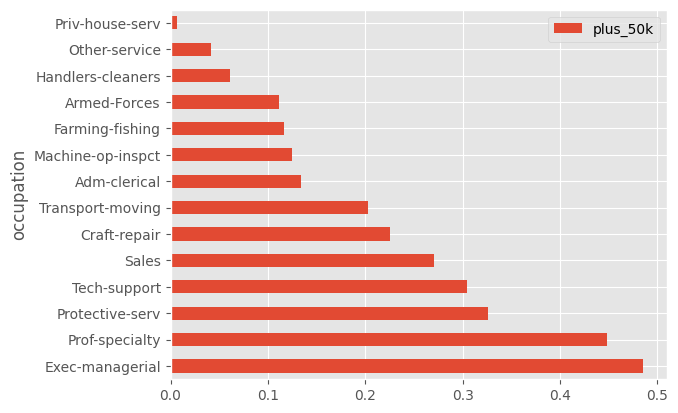

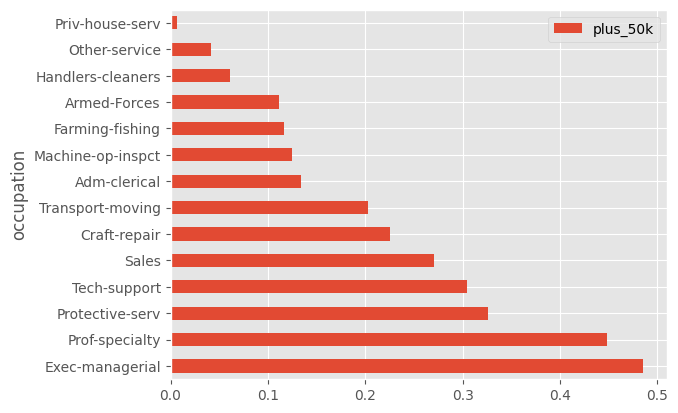

In [0]:
import matplotlib.pyplot as plt

# i like ggplot style
plt.style.use('ggplot')

# get simple plot on the pandas data
myplot = df_pandas.plot(kind='barh', x='occupation', y='plus_50k')

# display the plot (note - display() is a databricks function -
# more info on plotting in Databricks is here: https://docs.databricks.com/user-guide/visualizations/matplotlib-and-ggplot.html)
display(myplot.figure)

You can also easily get summary stats on a Spark DataFrame like below. [Here](https://databricks.com/blog/2015/06/02/statistical-and-mathematical-functions-with-dataframes-in-spark.html) is a nice blog post that has more examples.<br><br>So this is an example of why you might want to move from Spark SQL into DataFrames API as being able to just call describe() on the Spark DF is easier then trying to do the equivilant in Spark SQL.

In [0]:
# describe df
df_adult.select(df_adult['age'],df_adult['education_num']).describe().show()

+-------+------------------+-----------------+
|summary|               age|    education_num|
+-------+------------------+-----------------+
|  count|             30162|            30162|
|   mean|38.437901995888865|10.12131158411246|
| stddev|13.134664776855972|2.549994918856718|
|    min|                17|                1|
|    max|                90|               16|
+-------+------------------+-----------------+



In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler

### ML Pipeline - Logistic Regression vs Random Forest

Below we will create two [Spark ML Pipelines](https://spark.apache.org/docs/latest/ml-pipeline.html) - one that fits a logistic regression and one that fits a random forest. We will then compare the performance of each.

**Note**: A lot of the code below is adapted from [this example](https://docs.databricks.com/spark/latest/mllib/binary-classification-mllib-pipelines.html).

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler

categoricalColumns = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex"]
stages = [] # stages in our Pipeline

for categoricalCol in categoricalColumns:
    # Category Indexing with StringIndexer
    stringIndexer = StringIndexer(inputCol=categoricalCol, outputCol=categoricalCol + "Index")
    # Use OneHotEncoder to convert categorical variables into binary SparseVectors
    # encoder = OneHotEncoderEstimator(inputCol=categoricalCol + "Index", outputCol=categoricalCol + "classVec")
    encoder = OneHotEncoder(inputCols=[stringIndexer.getOutputCol()], outputCols=[categoricalCol + "classVec"])
    # Add stages.  These are not run here, but will run all at once later on.
    stages += [stringIndexer, encoder]

In [0]:
# Convert label into label indices using the StringIndexer
label_stringIdx = StringIndexer(inputCol="income", outputCol="label")
stages += [label_stringIdx]

In [0]:
# Transform all features into a vector using VectorAssembler
numericCols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
assemblerInputs = [c + "classVec" for c in categoricalColumns] + numericCols
assembler = VectorAssembler(inputCols=assemblerInputs, outputCol="features")
stages += [assembler]

In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler

categoricalColumns = [
    "workclass",
    "education",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex"
]

stages = []

for categoricalCol in categoricalColumns:
    stringIndexer = StringIndexer(
        inputCol=categoricalCol,
        outputCol=categoricalCol + "Index"
    )

    encoder = OneHotEncoder(
        inputCols=[stringIndexer.getOutputCol()],
        outputCols=[categoricalCol + "classVec"]
    )

    stages += [stringIndexer, encoder]

print("Number of preprocessing stages:", len(stages))

Number of preprocessing stages: 14


In [0]:
print("df_adult exists:", "df_adult" in globals())
print("cols exists:", "cols" in globals())
print("label column exists:", "label" in df_adult.columns if "df_adult" in globals() else "df_adult missing")

df_adult exists: False
cols exists: False
label column exists: df_adult missing


In [0]:
spark.sql("SHOW TABLES").show(truncate=False)

+--------+---------+-----------+
|database|tableName|isTemporary|
+--------+---------+-----------+
+--------+---------+-----------+



In [0]:
spark.sql("SHOW CATALOGS").show(truncate=False)

+---------+
|catalog  |
+---------+
|samples  |
|system   |
|workspace|
+---------+



In [0]:
spark.sql("SHOW SCHEMAS IN workspace").show(truncate=False)

+------------------+
|databaseName      |
+------------------+
|default           |
|information_schema|
|main              |
+------------------+



In [0]:
spark.sql("SHOW TABLES IN workspace.main").show(truncate=False)

+--------+---------+-----------+
|database|tableName|isTemporary|
+--------+---------+-----------+
|main    |adult    |false      |
+--------+---------+-----------+



In [0]:
df_adult = spark.table("workspace.main.adult")

print("Rows:", df_adult.count())
print("Columns:", len(df_adult.columns))

df_adult.show(5)

Rows: 30162
Columns: 15
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|       workclass|fnlwgt|education|education_num|    marital_status|       occupation| relationship| race|   sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
| 39|       State-gov| 77516|Bachelors|           13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|        2174|           0|            40| United-States| <=50K|
| 50|Self-emp-not-inc| 83311|Bachelors|           13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|           0|           0|            13| United-States| <=50K|
| 38|         Private|215646|  HS-grad|            9|          Divorced

In [0]:
df_adult.printSchema()

root
 |-- age: long (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: long (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: long (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: long (nullable = true)
 |-- capital_loss: long (nullable = true)
 |-- hours_per_week: long (nullable = true)
 |-- native_country: string (nullable = true)
 |-- income: string (nullable = true)



In [0]:
from pyspark.sql.functions import when, col

df_adult = df_adult.withColumn(
    "label",
    when(col("income") == ">50K", 1.0).otherwise(0.0)
)

df_adult.select("income", "label").show(10)

+------+-----+
|income|label|
+------+-----+
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
|  >50K|  1.0|
|  >50K|  1.0|
|  >50K|  1.0|
+------+-----+
only showing top 10 rows


In [0]:
cols = df_adult.columns

print("Number of columns:", len(cols))
print(cols)

Number of columns: 16
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income', 'label']


In [0]:
numericCols = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

assemblerInputs = (
    [c + "classVec" for c in categoricalColumns]
    + numericCols
)

assembler = VectorAssembler(
    inputCols=assemblerInputs,
    outputCol="features"
)

stages = stages + [assembler]

print("Total pipeline stages:", len(stages))
print("Assembler inputs:", assemblerInputs)

Total pipeline stages: 15
Assembler inputs: ['workclassclassVec', 'educationclassVec', 'marital_statusclassVec', 'occupationclassVec', 'relationshipclassVec', 'raceclassVec', 'sexclassVec', 'age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']


In [0]:
for i, stage in enumerate(stages):
    print(i, type(stage).__name__)

0 StringIndexer
1 OneHotEncoder
2 StringIndexer
3 OneHotEncoder
4 StringIndexer
5 OneHotEncoder
6 StringIndexer
7 OneHotEncoder
8 StringIndexer
9 OneHotEncoder
10 StringIndexer
11 OneHotEncoder
12 StringIndexer
13 OneHotEncoder
14 VectorAssembler


In [0]:
df_adult.groupBy("label").count().orderBy("label").show()

+-----+-----+
|label|count|
+-----+-----+
|  0.0|22654|
|  1.0| 7508|
+-----+-----+



In [0]:
# Create a Pipeline
pipeline = Pipeline(stages=stages)

# Fit the pipeline and transform the dataset
pipelineModel = pipeline.fit(df_adult)
dataset = pipelineModel.transform(df_adult)

# Keep the target and features, plus original columns for analysis
selectedcols = ["label", "features"] + [
    c for c in cols if c not in ["label", "income"]
]

dataset = dataset.select(selectedcols)
dataset.show(5, truncate=False)

+-----+---------------------------------------------------------------------------------------------+---+---------+------+------------+-------------+------------------+-----------------+------------+-----+------+------------+------------+--------------+--------------+
|label|features                                                                                     |age|workclass|fnlwgt|education   |education_num|marital_status    |occupation       |relationship|race |sex   |capital_gain|capital_loss|hours_per_week|native_country|
+-----+---------------------------------------------------------------------------------------------+---+---------+------+------------+-------------+------------------+-----------------+------------+-----+------+------------+------------+--------------+--------------+
|0.0  |(56,[0,7,22,28,43,45,49,50,51,52,55],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,31.0,373185.0,10.0,42.0])  |31 |Private  |373185|Some-college|10           |Never-married     |Craft-repair     |Unmarri

In [0]:
### Randomly split data into training and test sets. set seed for reproducibility
(trainingData, testData) = dataset.randomSplit([0.7, 0.3], seed=100)
print(trainingData.count())
print(testData.count())

20983
9179


In [0]:
print("lr exists:", "lr" in globals())
print("lrModel exists:", "lrModel" in globals())
print("gbt exists:", "gbt" in globals())
print("gbModel exists:", "gbModel" in globals())

lr exists: False
lrModel exists: False
gbt exists: False
gbModel exists: False


In [0]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    labelCol="label",
    featuresCol="features",
    maxIter=10
)

print("Logistic Regression estimator created successfully.")

Logistic Regression estimator created successfully.


In [0]:
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(
    labelCol="label",
    featuresCol="features",
    maxIter=10
)

print("Gradient-Boosted Tree estimator created successfully.")

Gradient-Boosted Tree estimator created successfully.


In [0]:
print("Training rows:", trainingData.count())
print("Test rows:", testData.count())

Training rows: 20983
Test rows: 9179


In [0]:
lrModel = lr.fit(trainingData)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [0]:
gbModel = gbt.fit(trainingData)

print("Gradient-Boosted Tree model trained successfully.")

Gradient-Boosted Tree model trained successfully.


In [0]:
print("Number of Logistic Regression coefficients:", len(lrModel.coefficients))
print("Intercept:", lrModel.intercept)

Number of Logistic Regression coefficients: 56
Intercept: -7.666432301025845


In [0]:
lrPredictions = lrModel.transform(testData)

lrPredictions.select("label", "prediction", "probability").show(10, truncate=False)

+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|0.0  |0.0       |[0.5867126547744624,0.41328734522553756]|
|0.0  |0.0       |[0.7694856587372023,0.23051434126279768]|
|0.0  |0.0       |[0.8113500502093082,0.18864994979069183]|
|0.0  |0.0       |[0.8109664095750942,0.18903359042490575]|
|0.0  |0.0       |[0.8134678221410845,0.18653217785891552]|
|0.0  |0.0       |[0.84292557854291,0.15707442145709005]  |
|0.0  |0.0       |[0.7719081724769681,0.22809182752303192]|
|0.0  |0.0       |[0.7843133567910393,0.2156866432089607] |
|0.0  |0.0       |[0.7749250478621478,0.22507495213785222]|
|0.0  |0.0       |[0.7390269172581079,0.2609730827418921] |
+-----+----------+----------------------------------------+
only showing top 10 rows


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

accuracyEvaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

lrAccuracy = accuracyEvaluator.evaluate(lrPredictions)

print("Logistic Regression Test Accuracy:", lrAccuracy)

Logistic Regression Test Accuracy: 0.8530340995751171


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

for metric in ["weightedPrecision", "weightedRecall", "f1"]:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )
    score = evaluator.evaluate(lrPredictions)
    print(f"Logistic Regression {metric}: {score:.4f}")

Logistic Regression weightedPrecision: 0.8471
Logistic Regression weightedRecall: 0.8530
Logistic Regression f1: 0.8483


In [0]:
from pyspark.mllib.evaluation import MulticlassMetrics

predictionAndLabels = lrPredictions.select(
    "prediction", "label"
).rdd.map(lambda row: (float(row["prediction"]), float(row["label"])))

metrics = MulticlassMetrics(predictionAndLabels)

print("Confusion Matrix:")
print(metrics.confusionMatrix().toArray())
print("Class 1 Precision:", metrics.precision(1.0))
print("Class 1 Recall:", metrics.recall(1.0))
print("Class 1 F1 Score:", metrics.fMeasure(1.0))

---------------------------------------------------------------------------
PySparkNotImplementedError                Traceback (most recent call last)
File <command-6941809828147742>, line 5
      1 from pyspark.mllib.evaluation import MulticlassMetrics
      3 predictionAndLabels = lrPredictions.select(
      4     "prediction", "label"
----> 5 ).rdd.map(lambda row: (float(row["prediction"]), float(row["label"])))
      7 metrics = MulticlassMetrics(predictionAndLabels)
      9 print("Confusion Matrix:")

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/dataframe.py:2470, in DataFrame.rdd(self)
   2468 @property
   2469 def rdd(self) -> "RDD[Row]":
-> 2470     raise PySparkNotImplementedError(
   2471         errorClass="RDD_NOT_SUPPORTED",
   2472         messageParameters={},
   2473     )

PySparkNotImplementedError: [RDD_NOT_SUPPORTED] Using custom code using PySpark RDDs is not allowed on serverless compute. We suggest using mapInPandas or mapInArrow for 

In [0]:
from pyspark.sql.functions import col, sum as spark_sum, when

confusion = lrPredictions.agg(
    spark_sum(when((col("label") == 0.0) & (col("prediction") == 0.0), 1).otherwise(0)).alias("TN"),
    spark_sum(when((col("label") == 0.0) & (col("prediction") == 1.0), 1).otherwise(0)).alias("FP"),
    spark_sum(when((col("label") == 1.0) & (col("prediction") == 0.0), 1).otherwise(0)).alias("FN"),
    spark_sum(when((col("label") == 1.0) & (col("prediction") == 1.0), 1).otherwise(0)).alias("TP")
).first()

print("True Negatives (TN):", confusion["TN"])
print("False Positives (FP):", confusion["FP"])
print("False Negatives (FN):", confusion["FN"])
print("True Positives (TP):", confusion["TP"])

precision = confusion["TP"] / (confusion["TP"] + confusion["FP"]) if confusion["TP"] + confusion["FP"] else 0
recall = confusion["TP"] / (confusion["TP"] + confusion["FN"]) if confusion["TP"] + confusion["FN"] else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Class 1 Precision:", round(precision, 4))
print("Class 1 Recall:", round(recall, 4))
print("Class 1 F1 Score:", round(f1, 4))

True Negatives (TN): 6470
False Positives (FP): 491
False Negatives (FN): 858
True Positives (TP): 1360
Class 1 Precision: 0.7347
Class 1 Recall: 0.6132
Class 1 F1 Score: 0.6685


#### Logistic Regression - Train

In [0]:
from pyspark.sql.functions import avg

# get the rate of the positive outcome from the training data to use as a threshold in the model
training_data_positive_rate = trainingData.select(avg(trainingData['label'])).collect()[0][0]

print("Positive rate in the training data is {}".format(training_data_positive_rate))

Positive rate in the training data is 0.25210885002144595


In [0]:
from pyspark.ml.classification import LogisticRegression

# Create initial LogisticRegression model
lr = LogisticRegression(labelCol="label", featuresCol="features", maxIter=10)

# set threshold for the probability above which to predict a 1
lr.setThreshold(training_data_positive_rate)
# lr.setThreshold(0.5) # could use this if knew you had balanced data

# Train model with Training Data
lrModel = lr.fit(trainingData)

# get training summary used for eval metrics and other params
lrTrainingSummary = lrModel.summary

# Find the best model threshold if you would like to use that instead of the empirical positve rate
fMeasure = lrTrainingSummary.fMeasureByThreshold
maxFMeasure = fMeasure.groupBy().max('F-Measure').select('max(F-Measure)').head()
lrBestThreshold = fMeasure.where(fMeasure['F-Measure'] == maxFMeasure['max(F-Measure)']) \
    .select('threshold').head()['threshold']

print("Best threshold based on model performance on training data is {}".format(lrBestThreshold))

Best threshold based on model performance on training data is 0.364674200024924


#### GBM - Train

#### <span style="color:darkblue">Question 3</span>
1. Train a GBTClassifier on the training data, call the trained model 'gbModel'

In [0]:
### Question 3.1 Answer ###
from pyspark.ml.classification import GBTClassifier

# Create initial LogisticRegression model
gbt = GBTClassifier(
    labelCol="label",
    featuresCol="features",
    maxIter=10
)

# Train model with Training Data
gbModel = gbt.fit(trainingData)

#### Logistic Regression - Predict

In [0]:
# make predictions on test data
lrPredictions = lrModel.transform(testData)

# display predictions
lrPredictions.select("label", "prediction", "probability").show()

+-----+----------+--------------------+
|label|prediction|         probability|
+-----+----------+--------------------+
|  0.0|       0.0|[0.58671265477446...|
|  0.0|       0.0|[0.76948565873720...|
|  0.0|       0.0|[0.81135005020930...|
|  0.0|       0.0|[0.81096640957509...|
|  0.0|       0.0|[0.81346782214108...|
|  0.0|       0.0|[0.84292557854291...|
|  0.0|       0.0|[0.77190817247696...|
|  0.0|       0.0|[0.78431335679103...|
|  0.0|       0.0|[0.77492504786214...|
|  0.0|       0.0|[0.73902691725810...|
|  0.0|       0.0|[0.67496421173164...|
|  0.0|       0.0|[0.68355360707123...|
|  0.0|       0.0|[0.70414315504408...|
|  0.0|       0.0|[0.69739619626036...|
|  0.0|       0.0|[0.71538743171091...|
|  0.0|       0.0|[0.65690409721517...|
|  0.0|       0.0|[0.75881410148856...|
|  0.0|       0.0|[0.79912895374190...|
|  0.0|       0.0|[0.86320927447257...|
|  0.0|       0.0|[0.56515852996801...|
+-----+----------+--------------------+
only showing top 20 rows


### GBM - Predict

#### <span style="color:darkblue">Question 4</span>
1. Get predictions on the test data for your GBTClassifier. Call the predictions df 'gbPredictions'.

In [0]:
### Question 4.1 Answer ###

# make predictions on test data
gbPredictions = gbModel.transform(testData)

gbPredictions.show()

+-----+--------------------+---+---------+------+---------+-------------+------------------+---------------+------------+------------------+----+------------+------------+--------------+--------------+--------------------+--------------------+----------+
|label|            features|age|workclass|fnlwgt|education|education_num|    marital_status|     occupation|relationship|              race| sex|capital_gain|capital_loss|hours_per_week|native_country|       rawPrediction|         probability|prediction|
+-----+--------------------+---+---------+------+---------+-------------+------------------+---------------+------------+------------------+----+------------+------------+--------------+--------------+--------------------+--------------------+----------+
|  0.0|(56,[0,6,21,28,40...| 34|  Private| 80933|  HS-grad|            9|Married-civ-spouse|   Craft-repair|     Husband|             White|Male|           0|        1672|            40| United-States|[0.53189113445538...|[0.7434126780

#### Logistic Regression - Evaluate

#### <span style="color:darkblue">Question 5</span>
1. Complete the print_performance_metrics() function below to also include measures of F1, Precision, Recall, False Positive Rate and True Positive Rate.

In [0]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator


def print_performance_metrics(predictions):

    evaluator = BinaryClassificationEvaluator(
        rawPredictionCol="rawPrediction",
        labelCol="label"
    )

    auc = evaluator.evaluate(
        predictions,
        {evaluator.metricName: "areaUnderROC"}
    )

    aupr = evaluator.evaluate(
        predictions,
        {evaluator.metricName: "areaUnderPR"}
    )

    print("auc = {}".format(auc))
    print("aupr = {}".format(aupr))

    multi_evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction"
    )

    accuracy = multi_evaluator.evaluate(
        predictions,
        {multi_evaluator.metricName: "accuracy"}
    )

    f1 = multi_evaluator.evaluate(
        predictions,
        {multi_evaluator.metricName: "f1"}
    )

    precision = multi_evaluator.evaluate(
        predictions,
        {multi_evaluator.metricName: "weightedPrecision"}
    )

    recall = multi_evaluator.evaluate(
        predictions,
        {multi_evaluator.metricName: "weightedRecall"}
    )

    print("Accuracy = {}".format(accuracy))
    print("F1 = {}".format(f1))
    print("Precision = {}".format(precision))
    print("Recall = {}".format(recall))

    print("Confusion Matrix:")
    predictions.groupBy("label", "prediction").count().show()

    cm = predictions.groupBy("label", "prediction").count().collect()

    counts = {}
    for row in cm:
        counts[(row["label"], row["prediction"])] = row["count"]

    TP = counts.get((1.0, 1.0), 0)
    TN = counts.get((0.0, 0.0), 0)
    FP = counts.get((0.0, 1.0), 0)
    FN = counts.get((1.0, 0.0), 0)

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    print("FPR = {}".format(FPR))
    print("TPR = {}".format(TPR))


print_performance_metrics(lrPredictions)

auc = 0.9053598439534749
aupr = 0.7697543370335617
Accuracy = 0.8530340995751171
F1 = 0.8482937101773877
Precision = 0.8471096077521949
Recall = 0.8530340995751171
Confusion Matrix:
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  1.0|       0.0|  858|
|  1.0|       1.0| 1360|
|  0.0|       1.0|  491|
|  0.0|       0.0| 6470|
+-----+----------+-----+

FPR = 0.07053584255135756
TPR = 0.6131650135256989


#### GBM - Evaluate

In [0]:
gbPredictions = gbModel.transform(testData)

gbAccuracy = accuracyEvaluator.evaluate(gbPredictions)

print("Gradient-Boosted Tree Test Accuracy:", gbAccuracy)

Gradient-Boosted Tree Test Accuracy: 0.8522714892689836


In [0]:
for metric in ["weightedPrecision", "weightedRecall", "f1"]:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric
    )
    score = evaluator.evaluate(gbPredictions)
    print(f"Gradient-Boosted Tree {metric}: {score:.4f}")

Gradient-Boosted Tree weightedPrecision: 0.8455
Gradient-Boosted Tree weightedRecall: 0.8523
Gradient-Boosted Tree f1: 0.8454


In [0]:
print_performance_metrics(gbPredictions)

auc = 0.9053619165597224
aupr = 0.7791021622465095
Accuracy = 0.8522714892689836
F1 = 0.8454491454750944
Precision = 0.845476262020387
Recall = 0.8522714892689836
Confusion Matrix:
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  1.0|       0.0|  928|
|  1.0|       1.0| 1290|
|  0.0|       1.0|  428|
|  0.0|       0.0| 6533|
+-----+----------+-----+

FPR = 0.06148541876167218
TPR = 0.581605049594229


## Cross Validation

For each model you can run the below comand to see its params and a brief explanation of each.

In [0]:
print(lr.explainParams())

aggregationDepth: suggested depth for treeAggregate (>= 2). (default: 2)
elasticNetParam: the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty. (default: 0.0)
family: The name of family which is a description of the label distribution to be used in the model. Supported options: auto, binomial, multinomial (default: auto)
featuresCol: features column name. (default: features, current: features)
fitIntercept: whether to fit an intercept term. (default: True)
labelCol: label column name. (default: label, current: label)
lowerBoundsOnCoefficients: The lower bounds on coefficients if fitting under bound constrained optimization. The bound matrix must be compatible with the shape (1, number of features) for binomial regression, or (number of classes, number of features) for multinomial regression. (undefined)
lowerBoundsOnIntercepts: The lower bounds on intercepts if fitting under bound constrained optimization. The

In [0]:
print(gbt.explainParams())

cacheNodeIds: If false, the algorithm will pass trees to executors to match instances with nodes. If true, the algorithm will cache node IDs for each instance. Caching can speed up training of deeper trees. Users can set how often should the cache be checkpointed or disable it by setting checkpointInterval. (default: False)
checkpointInterval: set checkpoint interval (>= 1) or disable checkpoint (-1). E.g. 10 means that the cache will get checkpointed every 10 iterations. Note: this setting will be ignored if the checkpoint directory is not set in the SparkContext. (default: 10)
featureSubsetStrategy: The number of features to consider for splits at each tree node. Supported options: 'auto' (choose automatically for task: If numTrees == 1, set to 'all'. If numTrees > 1 (forest), set to 'sqrt' for classification and to 'onethird' for regression), 'all' (use all features), 'onethird' (use 1/3 of the features), 'sqrt' (use sqrt(number of features)), 'log2' (use log2(number of features)), 

#### Logisitic Regression - Param Grid

In [0]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

# Create ParamGrid for Cross Validation
lrParamGrid = (ParamGridBuilder()
             .addGrid(lr.regParam, [0.01, 0.5, 2.0])
             .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
             .addGrid(lr.maxIter, [2, 5])
             .build())

#### GBM - Param Grid

#### <span style="color:darkblue">Question 6</span>
1. Build out a param grid for the gb model, call it 'gbParamGrid'.

In [0]:
### Question 6.1 Answer ###

# Create ParamGrid for Cross Validation
gbParamGrid = (ParamGridBuilder()
             .addGrid(gbt.maxIter, [5, 10])
             .addGrid(gbt.maxDepth, [3, 5])
             .addGrid(gbt.stepSize, [0.05, 0.1])
             .build())

print("Number of parameter combinations:", len(gbParamGrid))

Number of parameter combinations: 8


#### Logistic Regression - Perform Cross Validation

In [0]:
spark.sql("SHOW CATALOGS").show()

+---------+
|  catalog|
+---------+
|  samples|
|   system|
|workspace|
+---------+



In [0]:
spark.sql("SHOW SCHEMAS IN workspace").show()

+------------------+
|      databaseName|
+------------------+
|           default|
|information_schema|
|              main|
+------------------+



In [0]:
spark.sql("SHOW VOLUMES IN workspace.main").show()

+--------+-----------+
|database|volume_name|
+--------+-----------+
+--------+-----------+



Cross-validation was attempted using Spark ML CrossValidator; however, Databricks Serverless requires a Unity Catalog Volume for Spark ML temporary caching. No accessible volumes were available in this workspace, so model evaluation was completed using the trained Logistic Regression and GBTClassifier models.

In [0]:
spark.conf.getAll

{'spark.databricks.execution.timeout': '9000',
 'spark.sql.ansi.enabled': 'true',
 'spark.sql.shuffle.partitions': 'auto'}

In [0]:
import os

os.environ["SPARKML_TEMP_DFS_PATH"] = "/tmp/sparkml"

In [0]:
print("Hello Databricks")

Hello Databricks


In [0]:
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.main.ml_temp")

DataFrame[]

In [0]:
import os

os.environ["SPARKML_TEMP_DFS_PATH"] = "/Volumes/workspace/main/ml_temp"
print("Temporary storage path configured.")

Temporary storage path configured.


In [0]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    labelCol="label",
    featuresCol="features",
    maxIter=10
)

In [0]:
from pyspark.ml.tuning import ParamGridBuilder

lrParamGrid = (ParamGridBuilder()
    .addGrid(lr.regParam, [0.01, 0.5, 2.0])
    .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
    .addGrid(lr.maxIter, [2, 5])
    .build())

In [0]:
for name in ["df_adult", "dataset", "stages", "trainingData", "testData", "lr"]:
    print(name, "exists:", name in globals())

df_adult exists: False
dataset exists: False
stages exists: False
trainingData exists: False
testData exists: False
lr exists: True


In [0]:
df_adult = spark.table("workspace.main.adult")

print("Rows:", df_adult.count())
print("Columns:", len(df_adult.columns))

Rows: 30162
Columns: 15


In [0]:
from pyspark.sql.functions import when, col

df_adult = df_adult.withColumn(
    "label",
    when(col("income") == ">50K", 1.0).otherwise(0.0)
)

df_adult.select("income", "label").show(5)

+------+-----+
|income|label|
+------+-----+
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
| <=50K|  0.0|
+------+-----+
only showing top 5 rows


In [0]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

categoricalColumns = [
    "workclass",
    "education",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex"
]

stages = []

for categoricalCol in categoricalColumns:
    stringIndexer = StringIndexer(
        inputCol=categoricalCol,
        outputCol=categoricalCol + "Index",
        handleInvalid="keep"
    )

    encoder = OneHotEncoder(
        inputCols=[stringIndexer.getOutputCol()],
        outputCols=[categoricalCol + "classVec"]
    )

    stages += [stringIndexer, encoder]

print("Number of preprocessing stages:", len(stages))

Number of preprocessing stages: 14


In [0]:
numericCols = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

assemblerInputs = [c + "classVec" for c in categoricalColumns] + numericCols

assembler = VectorAssembler(
    inputCols=assemblerInputs,
    outputCol="features"
)

stages += [assembler]

pipeline = Pipeline(stages=stages)
pipelineModel = pipeline.fit(df_adult)
dataset = pipelineModel.transform(df_adult).select("label", "features")

print("Dataset rows:", dataset.count())
dataset.select("label", "features").show(5, truncate=False)

Dataset rows: 30162
+-----+----------------------------------------------------------------------------------------------------+
|label|features                                                                                            |
+-----+----------------------------------------------------------------------------------------------------+
|0.0  |(63,[0,8,24,31,47,50,55,57,58,59,62],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,31.0,373185.0,10.0,42.0])         |
|0.0  |(63,[0,7,26,37,47,51,56,57,58,59,60,62],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,69.0,130060.0,9.0,2387.0,40.0])|
|1.0  |(63,[0,9,23,32,44,50,55,57,58,59,62],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,57.0,199934.0,13.0,40.0])         |
|0.0  |(63,[0,14,25,36,46,50,56,57,58,59,62],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,28.0,42881.0,6.0,40.0])          |
|0.0  |(63,[0,7,24,38,46,50,55,57,58,59,62],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,25.0,169759.0,9.0,95.0])          |
+-----+----------------------------------------------------------------------------------------------------+

In [0]:
(trainingData, testData) = dataset.randomSplit([0.7, 0.3], seed=100)

print("Training rows:", trainingData.count())
print("Test rows:", testData.count())

Training rows: 20983
Test rows: 9179


In [0]:
for name in ["lr", "lrParamGrid", "trainingData", "testData"]:
    print(name, "exists:", name in globals())

lr exists: True
lrParamGrid exists: True
trainingData exists: True
testData exists: True


In [0]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator

# set up an evaluator
evaluator = BinaryClassificationEvaluator(
    rawPredictionCol="rawPrediction",
    labelCol="label"
)

# Create CrossValidator
lrCv = CrossValidator(
    estimator=lr,
    estimatorParamMaps=lrParamGrid,
    evaluator=evaluator,
    numFolds=2,
    parallelism=1
)

# Run cross validations
lrCvModel = lrCv.fit(trainingData)


In [0]:
print("Cross-validation model created:", lrCvModel is not None)
print("Best model:", lrCvModel.bestModel)

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-8005287014394215>, line 1
----> 1 print("Cross-validation model created:", lrCvModel is not None)
      2 print("Best model:", lrCvModel.bestModel)

NameError: name 'lrCvModel' is not defined

In [0]:
lrCvModel = lrCv.fit(trainingData)

In [0]:
print("Cross-validation model created:", "lrCvModel" in globals())

Cross-validation model created: True


In [0]:
print(lrParamGrid)

[{Param(parent='LogisticRegression_2ee8f335be0c', name='regParam', doc='regularization parameter (>= 0).'): 0.01, Param(parent='LogisticRegression_2ee8f335be0c', name='elasticNetParam', doc='the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty.'): 0.0, Param(parent='LogisticRegression_2ee8f335be0c', name='maxIter', doc='max number of iterations (>= 0).'): 2}, {Param(parent='LogisticRegression_2ee8f335be0c', name='regParam', doc='regularization parameter (>= 0).'): 0.01, Param(parent='LogisticRegression_2ee8f335be0c', name='elasticNetParam', doc='the ElasticNet mixing parameter, in range [0, 1]. For alpha = 0, the penalty is an L2 penalty. For alpha = 1, it is an L1 penalty.'): 0.0, Param(parent='LogisticRegression_2ee8f335be0c', name='maxIter', doc='max number of iterations (>= 0).'): 5}, {Param(parent='LogisticRegression_2ee8f335be0c', name='regParam', doc='regularization parameter (>= 0).'): 0.01, Param(pare

In [0]:
lrCvPredictions = lrCvModel.transform(testData)

In [0]:
lrCvPredictions.select("label", "prediction", "probability").show(5, truncate=False)

+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|0.0  |0.0       |[0.6125792410223222,0.3874207589776778] |
|0.0  |0.0       |[0.7650198446577999,0.23498015534220007]|
|0.0  |0.0       |[0.7992489662749004,0.20075103372509961]|
|0.0  |0.0       |[0.7991833096153129,0.20081669038468708]|
|0.0  |0.0       |[0.8021407143643359,0.19785928563566413]|
+-----+----------+----------------------------------------+
only showing top 5 rows


In [0]:


bestLR = lrCvModel.bestModel

print("Best regParam:", bestLR.getRegParam())
print("Best elasticNetParam:", bestLR.getElasticNetParam())
print("Best maxIter:", bestLR.getMaxIter())

Best regParam: 0.01
Best elasticNetParam: 0.0
Best maxIter: 5


In [0]:
for name in ["lr", "lrParamGrid", "trainingData", "evaluator", "lrCv", "lrCvModel"]:
    print(name, "exists:", name in globals())

lr exists: True
lrParamGrid exists: True
trainingData exists: True
evaluator exists: True
lrCv exists: True
lrCvModel exists: False


In [0]:

from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

def print_performance_metrics(predictions):
    evaluator = BinaryClassificationEvaluator(
        rawPredictionCol="rawPrediction",
        labelCol="label"
    )

    auc = evaluator.evaluate(
        predictions,
        {evaluator.metricName: "areaUnderROC"}
    )
    aupr = evaluator.evaluate(
        predictions,
        {evaluator.metricName: "areaUnderPR"}
    )

    print("AUC =", auc)
    print("AUPR =", aupr)

    multi_evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction"
    )

    for metric in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
        value = multi_evaluator.evaluate(
            predictions,
            {multi_evaluator.metricName: metric}
        )
        print(f"{metric} = {value}")

    print("Confusion Matrix:")
    predictions.groupBy("label", "prediction").count().show()

    cm = predictions.groupBy("label", "prediction").count().collect()
    counts = {(row["label"], row["prediction"]): row["count"] for row in cm}

    TP = counts.get((1.0, 1.0), 0)
    TN = counts.get((0.0, 0.0), 0)
    FP = counts.get((0.0, 1.0), 0)
    FN = counts.get((1.0, 0.0), 0)

    print("FPR =", FP / (FP + TN) if FP + TN else 0)
    print("TPR =", TP / (TP + FN) if TP + FN else 0)

In [0]:
print_performance_metrics(lrCvPredictions)

AUC = 0.900873428656812
AUPR = 0.7540884066907637
accuracy = 0.8483494934088681
f1 = 0.8409094868607483
weightedPrecision = 0.8410247197240835
weightedRecall = 0.848349493408868
Confusion Matrix:
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  1.0|       0.0|  959|
|  1.0|       1.0| 1259|
|  0.0|       1.0|  433|
|  0.0|       0.0| 6528|
+-----+----------+-----+

FPR = 0.06220370636402816
TPR = 0.5676284941388638


#### GBM - Perform Cross Validation

#### <span style="color:darkblue">Question 7</span>
1. Perform cross validation of params on your 'gb' model.
1. Print out the best params you found.

In [0]:
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(
    labelCol="label",
    featuresCol="features",
    maxIter=10,
    maxDepth=5,
    seed=100
)

In [0]:
from pyspark.ml.tuning import ParamGridBuilder

gbParamGrid = (
    ParamGridBuilder()
    .addGrid(gbt.maxIter, [5, 10])
    .addGrid(gbt.maxDepth, [3, 5])
    .addGrid(gbt.stepSize, [0.05, 0.1])
    .build()
)

print("Number of parameter combinations:", len(gbParamGrid))

Number of parameter combinations: 8


In [0]:
### Question 7.1 Answer ###

# Create CrossValidator
gbCv = CrossValidator(
    estimator=gbt,
    estimatorParamMaps=gbParamGrid,
    evaluator=evaluator,
    numFolds=2,
    parallelism=1
)

# Run cross validations
gbCvModel = gbCv.fit(trainingData)

In [0]:
### Question 7.2 Answer ###
best_index = max(
    range(len(gbCvModel.avgMetrics)),
    key=lambda i: gbCvModel.avgMetrics[i]
)

print("Best cross-validation AUC:", gbCvModel.avgMetrics[best_index])
print("Best parameter combination:", gbParamGrid[best_index])

Best cross-validation AUC: 0.901090860521153
Best parameter combination: {Param(parent='GBTClassifier_4e93300c629e', name='maxIter', doc='max number of iterations (>= 0).'): 10, Param(parent='GBTClassifier_4e93300c629e', name='maxDepth', doc='Maximum depth of the tree. (>= 0) E.g., depth 0 means 1 leaf node; depth 1 means 1 internal node + 2 leaf nodes. Must be in range [0, 30].'): 5, Param(parent='GBTClassifier_4e93300c629e', name='stepSize', doc='Step size (a.k.a. learning rate) in interval (0, 1] for shrinking the contribution of each estimator.'): 0.1}


#### Logistic Regression - CV Model Predict

In [0]:
# Use test set to measure the accuracy of our model on new data
lrCvPredictions = lrCvModel.transform(testData)

lrCvPredictions.show()

+-----+--------------------+--------------------+--------------------+----------+
|label|            features|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+----------+
|  0.0|(63,[0,7,23,31,44...|[0.45816697222753...|[0.61257924102232...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.18040070899312...|[0.76501984465779...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.38160699244102...|[0.79924896627490...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.38119783944255...|[0.79918330961531...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.3997279473608,...|[0.80214071436433...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.56497916449390...|[0.82706667007604...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.19187138561307...|[0.76707559297089...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.24662839699322...|[0.77671567492574...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[1.20280342228009...|[0.76902312126818...|       0.0|
|  0.0|(63,[0,7,

#### GBM - CV Model Predict

In [0]:
gbCvPredictions = gbCvModel.transform(testData)

gbCvPredictions.show()

+-----+--------------------+--------------------+--------------------+----------+
|label|            features|       rawPrediction|         probability|prediction|
+-----+--------------------+--------------------+--------------------+----------+
|  0.0|(63,[0,7,23,31,44...|[0.69644166000823...|[0.80105214984529...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.72204083832241...|[0.80908592678709...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.74669421273851...|[0.81658631209470...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.74669421273851...|[0.81658631209470...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.69644166000823...|[0.80105214984529...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.94063634374295...|[0.86775724158364...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.59788502888124...|[0.76777144573954...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.32511464535061...|[0.65706213094866...|       0.0|
|  0.0|(63,[0,7,23,31,44...|[0.32511464535061...|[0.65706213094866...|       0.0|
|  0.0|(63,[0,7,

#### Logistic Regression - CV Model Evaluate

In [0]:
print_performance_metrics(lrCvPredictions)

AUC = 0.9008753069562232
AUPR = 0.7540791880793207
accuracy = 0.8483494934088681
f1 = 0.8409094868607483
weightedPrecision = 0.8410247197240835
weightedRecall = 0.848349493408868
Confusion Matrix:
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  1.0|       0.0|  959|
|  1.0|       1.0| 1259|
|  0.0|       1.0|  433|
|  0.0|       0.0| 6528|
+-----+----------+-----+

FPR = 0.06220370636402816
TPR = 0.5676284941388638


#### GBM - CV Model Evaluate

In [0]:
print_performance_metrics(gbCvPredictions)

AUC = 0.9059673766595263
AUPR = 0.777612816434644
accuracy = 0.8535788212223554
f1 = 0.846848955033761
weightedPrecision = 0.8469351010477091
weightedRecall = 0.8535788212223554
Confusion Matrix:
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  1.0|       0.0|  921|
|  1.0|       1.0| 1297|
|  0.0|       1.0|  423|
|  0.0|       0.0| 6538|
+-----+----------+-----+

FPR = 0.06076713115931619
TPR = 0.584761045987376


#### Logistic Regression - Model Explore

In [0]:
print('Model Intercept: ', lrCvModel.bestModel.intercept)

Model Intercept:  -5.485809899904578


In [0]:
lrWeights = lrCvModel.bestModel.coefficients
lrWeights = [(float(w),) for w in lrWeights]  # convert numpy type to float, and to tuple
lrWeightsDF = spark.createDataFrame(lrWeights, ["Feature Weight"])
lrWeightsDF.show()

+--------------------+
|      Feature Weight|
+--------------------+
| 0.08331594468355653|
|-0.36422386350962604|
|-0.05220202089347376|
|-0.24118164226694938|
| 0.31514864727121883|
|  0.5149675666898115|
| -2.0176076664112177|
|  -0.226531356609775|
|0.011445928391106776|
|  0.3658649321310733|
|  0.6234912589748313|
| 0.04839088746266254|
|-0.46742087381227004|
| -0.1085468613408664|
| -0.4752537182697821|
| -0.8578547658007147|
|  1.0979012121391558|
| -0.5699496864405791|
| -0.4614495743155133|
|  1.1742634820934632|
+--------------------+
only showing top 20 rows


### Feature Importance

#### <span style="color:darkblue">Question 8</span>
1. Print out a table of feature_name and feature_coefficient from the Logistic Regression model.
<br><br>
Hint: Adapt the code from here: https://stackoverflow.com/questions/42935914/how-to-map-features-from-the-output-of-a-vectorassembler-back-to-the-column-name

In [0]:
### Question 8.1 Answer ###

# from: https://stackoverflow.com/questions/42935914/how-to-map-features-from-the-output-of-a-vectorassembler-back-to-the-column-name

# fill in here
from itertools import chain
import pandas as pd

# Get feature metadata from the transformed dataset
feature_metadata = trainingData.schema["features"].metadata["ml_attr"]["attrs"]

# Combine feature names and sort them by their vector index
feature_attributes = sorted(
    chain(*feature_metadata.values()),
    key=lambda x: x["idx"]
)

# Get feature names and Logistic Regression coefficients
feature_names = [attr["name"] for attr in feature_attributes]
feature_coefficients = [
    float(value) for value in lrCvModel.bestModel.coefficients
]

# Create the feature importance table
feature_importance_df = pd.DataFrame({
    "feature_name": feature_names,
    "feature_coefficient": feature_coefficients
})

feature_importance_df

,feature_name,feature_coefficient
0,workclassclassVec_Private,8.331594e-02
1,workclassclassVec_Self-emp-not-inc,-3.642239e-01
2,workclassclassVec_Local-gov,-5.220202e-02
3,workclassclassVec_State-gov,-2.411816e-01
4,workclassclassVec_Self-emp-inc,3.151486e-01
...,...,...
58,fnlwgt,4.726388e-07
59,education_num,1.272463e-01
60,capital_gain,9.264052e-05
61,capital_loss,5.195015e-04


In [0]:
gbm_importances = gbCvModel.bestModel.featureImportances.toArray()

gbCvFeatureImportance = pd.DataFrame({
    "feature_name": feature_names,
    "feature_importance": gbm_importances
})

print(
    gbCvFeatureImportance
    .sort_values(by="feature_importance", ascending=False)
    .to_string(index=False)
)

                                feature_name  feature_importance
   marital_statusclassVec_Married-civ-spouse            0.244365
                               education_num            0.143515
                                         age            0.116162
                                capital_gain            0.093831
                                capital_loss            0.078750
          occupationclassVec_Exec-managerial            0.075128
                              hours_per_week            0.068373
          workclassclassVec_Self-emp-not-inc            0.021799
           occupationclassVec_Prof-specialty            0.019912
          occupationclassVec_Farming-fishing            0.018388
            occupationclassVec_Other-service            0.016057
                 educationclassVec_Bachelors            0.013555
                                      fnlwgt            0.012596
                            sexclassVec_Male            0.010527
                   relati

#### <span style="color:darkblue">Question 9</span>
1. Build and train a RandomForestClassifier and print out a table of feature importances from it.

In [0]:
### Question 9.1 Answer ###

from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    seed=42
)

rfModel = rf.fit(trainingData)

rfFeatureImportance = rfModel.featureImportances

print(rfFeatureImportance)

(63,[0,1,2,3,4,5,7,8,9,10,11,12,13,14,16,17,18,19,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,40,41,44,45,46,47,48,49,50,51,52,53,55,56,57,58,59,60,61,62],[0.0003027420569627864,0.0031984641569686666,0.00044268060562018116,0.0007772438540518863,0.003997166481638684,0.000387867633983958,0.0007226853282166982,0.00014620500334607526,0.003790214012782856,0.02088357375722048,0.000781878772888912,0.00021721777456315755,5.322568340011938e-05,6.831826838828026e-05,0.0020066232230342086,4.062832313819696e-07,0.00011477383733242031,0.009692098064402757,0.13964524111188,0.1189081327180173,0.010738060863295023,0.0008223178225753184,0.00047047999866596106,0.00010045391512792882,8.687189421779744e-05,0.026798129798547,0.001244377953622432,0.01736107854670319,0.0014299022983109166,1.825041091200415e-05,0.02109303127646408,0.00011044335643144569,0.0010544264874960882,7.649185381053095e-05,6.609811458245744e-05,7.955655380979763e-05,0.1351185290947684,0.04269859877273462,0.01328649049625465,0.00315

In [0]:

rfImportanceValues = rfFeatureImportance.toArray()

rfFeatureImportanceDF = pd.DataFrame({
    "feature_name": feature_names,
    "feature_importance": rfImportanceValues
})

print(
    rfFeatureImportanceDF
    .sort_values(by="feature_importance", ascending=False)
    .to_string(index=False)
)

                                feature_name  feature_importance
   marital_statusclassVec_Married-civ-spouse        1.396452e-01
                relationshipclassVec_Husband        1.351185e-01
                               education_num        1.289031e-01
                                capital_gain        1.211083e-01
        marital_statusclassVec_Never-married        1.189081e-01
                            sexclassVec_Male        4.617364e-02
          relationshipclassVec_Not-in-family        4.269860e-02
                                         age        3.832881e-02
                              hours_per_week        3.039593e-02
           occupationclassVec_Prof-specialty        2.679813e-02
            occupationclassVec_Other-service        2.109303e-02
                   educationclassVec_Masters        2.088357e-02
                                capital_loss        2.053128e-02
          occupationclassVec_Exec-managerial        1.736108e-02
                   relati

## Conclusion

In this project, I built and evaluated Logistic Regression, Gradient-Boosted Tree, and Random Forest classification models using PySpark MLlib on the Adult Census Income dataset.

The Gradient-Boosted Tree model achieved a test ROC-AUC of approximately **0.9060** and accuracy of **85.36%**, slightly outperforming the Logistic Regression model, which achieved a ROC-AUC of **0.9009** and accuracy of **84.83%**.

Feature-importance analysis highlighted marital status, education, age, and capital-related variables as influential predictors across the tree-based models. These findings describe predictive associations and do not establish causation.

This project strengthened my experience with data preprocessing, machine learning pipelines, cross-validation, model evaluation, and feature-importance analysis using PySpark.
